# Borrow a tuned model without losing its lineage

## tl;dr

Original model training/tuning belongs to the teammate; the repository author's contribution is metric-aware post-processing. Four older checkpoints and the exact team submission links were recovered, while best-team RoBERTa weights remain unresolved.

A public tuned RoBERTa fold loads all **202** tensors in current PyTorch/Transformers. After author-version fold recovery, raw Spearman **0.419363** is within **0.00010** of the author's log. Two-way calibration diagnostics gain **+0.010927** on average, but **18/30 targets worsen in each direction**. No new leaderboard or independent model-acceptance result is claimed.

The main lesson is operational: preserve the model's input/head contract and its evaluation population, then evaluate the postprocessor separately. This walkthrough uses public aggregate evidence only; no weights, IDs or credentials are needed.

## Context & Methods

The borrowed checkpoint retains the original authors' tuning, including domain adaptation/pseudo-labels, head/tail packing and learned weighting of 13 CLS states. We load it without training, using modern framework APIs. All state keys must match, and packing is checked against reviewed author functions.

### Key Assumptions

Original saved fold IDs are unavailable. Native GroupKFold reconstructions changed populations across numerical versions. An index-only reference container uses the author's documented versions, and modern inference is then compared with the saved log. Close reconciliation is not exact replay. The checkpoint was selected on that same population, so calibration half-split results remain conditional diagnostics. Full-fit scores are optimistic.

[Full interpretation and reproduction](../docs/public-checkpoint-probe.md) · [Team lineage](../docs/original-solution-lineage.md).

## Data

Load aggregate lineage and probe receipts. Private source notebooks, rows, fitted policies and checkpoint files remain outside Git. The existing historical and modern leaderboard rows stay separate from this borrowed model's diagnostics.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
root = Path.cwd() if (Path.cwd() / "docs").exists() else Path.cwd().parent
lineage = json.loads((root / "docs/original-solution-lineage.json").read_text())
probe = json.loads((root / "docs/public-checkpoint-probe.json").read_text())
assert probe["status"] == "completed" and probe["strictly_loaded_state_tensors"] == 202
assert probe["independent_checks"]["all_30_target_metrics_reconciled_in_each_direction"]
plt.rcParams.update({"figure.figsize": (9, 4.5), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.2})
display(pd.DataFrame([{"Model": r["model_directory"], "Head shape": str(r["head_kernel_shape"]),
                       "Numerical replay": r["full_inference_replayed"]}
                      for r in lineage["older_recovered_weights"]["models"]]))
print("Best-team checkpoint replay:", lineage["original_best_model_numerical_replay_claimed"])
print("Public checkpoint:", probe["plan"]["public_checkpoint"])

,Model,Head shape,Numerical replay
0,bert-base-uncased_q384_a512,"[2304, 30]",False
1,distilbert-base-uncased_q384_a512,"[2304, 30]",False
2,distilroberta-base_q384_a512,"[2304, 30]",False
3,distilroberta-base_q384_a512_weighted,"[2304, 30]",False


Best-team checkpoint replay: False
Public checkpoint: kashnitsky/google-qa-quest-labeling-bibimorph-model-3-roberta


## Results

### 1. Same-sized folds can contain different IDs

All populations contain 1,216 rows, yet membership changes. Higher native reconstruction scores are not model improvements. The common 476-row test predictions agree within 2.1e−6 across CPU/GPU, separately from population drift.

,Population,Rows,Reference IDs included,Raw Spearman
0,Current local native reconstruction,1216,312,0.482525
1,Current Kaggle native reconstruction,1216,247,0.495579
2,Author-version reference,1216,1216,0.419363


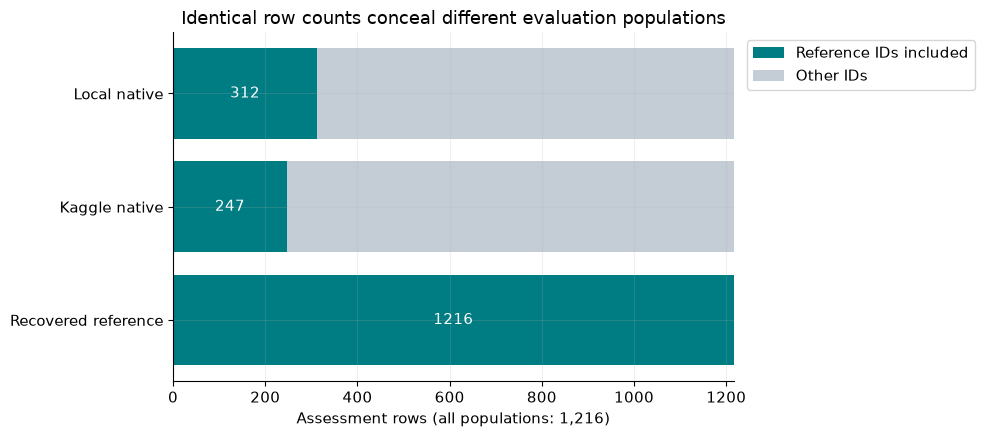

In [2]:
native = probe["native_reconstruction_diagnostics"]
rows = [{"Population": x["label"], "Rows": x["assessment_rows"],
         "Reference IDs included": x["reference_id_overlap"],
         "Raw Spearman": x["raw_spearman"]} for x in native]
rows.append({"Population": "Author-version reference", "Rows": probe["assessment_rows"],
             "Reference IDs included": probe["assessment_rows"],
             "Raw Spearman": probe["reference_raw_score"]["mean_spearman_30_zero_fallback"]})
populations = pd.DataFrame(rows)
display(populations.round(6))
fig, ax = plt.subplots(figsize=(10, 4.5))
y = np.arange(len(populations))
shared = populations["Reference IDs included"].to_numpy()
other = populations.Rows.to_numpy() - shared
ax.barh(y, shared, color="#007c83", label="Reference IDs included")
ax.barh(y, other, left=shared, color="#c4cdd5", label="Other IDs")
for i, count in enumerate(shared): ax.text(count / 2, i, str(count), ha="center", va="center", color="white")
ax.set(yticks=y, yticklabels=["Local native", "Kaggle native", "Recovered reference"],
       xlabel="Assessment rows (all populations: 1,216)",
       title="Identical row counts conceal different evaluation populations")
ax.invert_yaxis(); ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1)); fig.tight_layout(); plt.show()

The two native populations share only 234 IDs with each other. Restoring the documented numerical versions produces a fixed reference assignment and brings the raw score close to the author's log. Save that assignment; do not regenerate it from a fold number in a different environment.

In [3]:
observed = probe["reference_raw_score"]["mean_spearman_30_zero_fallback"]
author = probe["author_recorded_best_score"]
display(pd.Series({"Author recorded": author, "Modern reference-population result": observed,
                   "Difference": observed - author}, name="Spearman"))
assert abs((observed - author) - probe["raw_minus_author_record"]) < 1e-12
print("Independent metric reconciliation and policy reload:", probe["independent_checks"]["status"])
print("Reload maximum difference:", probe["independent_checks"]["candidate_reload_max_prediction_delta"])

Author recorded                       0.419461
Modern reference-population result    0.419363
Difference                           -0.000098
Name: Spearman, dtype: float64

Independent metric reconciliation and policy reload: passed
Reload maximum difference: 0.0


### 2. The macro gain is not uniform across targets

Calibrate on one question-group half and assess on the other, then reverse. Keep all 30 targets and the fixed original rounder. The mean half-split raw score is not the same as whole-population Spearman because rank correlation is not additive over partitions.

,Direction,Calibration rows,Assessment rows,Raw,Rounded,Delta
0,0,604,612,0.404067,0.419976,0.015909
1,1,612,604,0.431432,0.437377,0.005945


,direction,targets_improved,targets_worsened,targets_unchanged
0,0,10,18,2
1,1,11,18,1


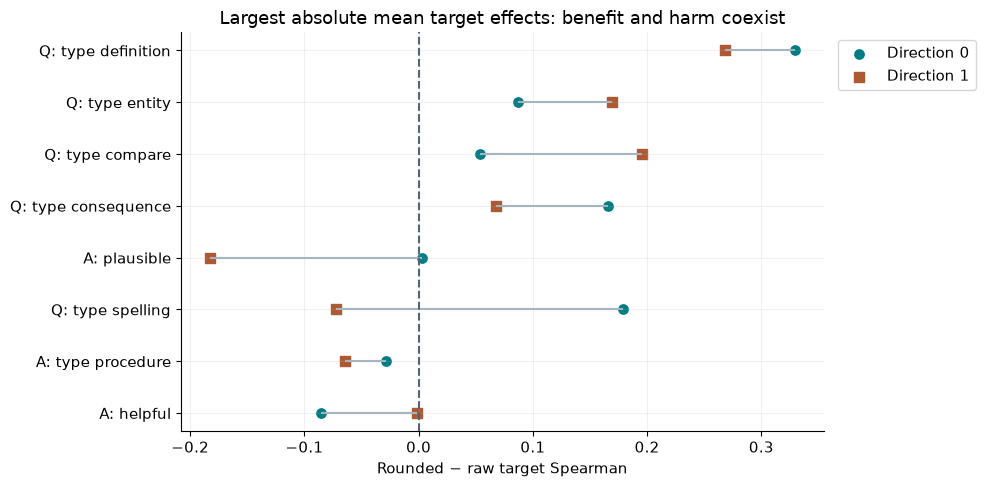

In [4]:
transfers = probe["calibration_transfers"]
summary = pd.DataFrame([{"Direction": x["direction"], "Calibration rows": x["calibration_rows"],
                         "Assessment rows": x["assessment_rows"],
                         "Raw": x["raw"]["mean_spearman_30_zero_fallback"],
                         "Rounded": x["rounded"]["mean_spearman_30_zero_fallback"],
                         "Delta": x["delta"]} for x in transfers])
display(summary.round(6))
assert abs(summary.Delta.mean() - probe["mean_paired_transfer_delta"]) < 1e-12
columns = list(transfers[0]["raw"]["per_target"])
deltas = pd.DataFrame({f"Direction {x['direction']}":
                       {c: x["rounded"]["per_target"][c] - x["raw"]["per_target"][c] for c in columns}
                       for x in transfers})
display(pd.DataFrame(probe["target_delta_analysis"]["directions"]))
assert [(deltas[c] < 0).sum() for c in deltas] == [18, 18]
selected = deltas.mean(axis=1).abs().nlargest(8).index
shown = deltas.loc[selected].iloc[::-1]
labels = [c.replace("question_", "Q: ").replace("answer_", "A: ").replace("_", " ") for c in shown.index]
fig, ax = plt.subplots(figsize=(10, 5))
y = np.arange(len(shown))
ax.hlines(y, shown.min(axis=1), shown.max(axis=1), color="#a7b3be")
for c, color, marker in zip(shown.columns, ["#007c83", "#ad5a33"], ["o", "s"]):
    ax.scatter(shown[c], y, label=c, color=color, marker=marker, s=45)
ax.axvline(0, color="#51657a", linestyle="--")
ax.set(yticks=y, yticklabels=labels, xlabel="Rounded − raw target Spearman",
       title="Largest absolute mean target effects: benefit and harm coexist")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1)); fig.tight_layout(); plt.show()

Definition improves strongly in both directions, while spelling changes sign and answer plausibility has a large negative effect in one direction. These are descriptive effects of these fitted policies/populations, not universal label-specific rules.

In [5]:
contributions = deltas.mean(axis=1) / 30
net = contributions.sum()
display(pd.Series({"All-30 mean paired gain": net,
                   "Definition contribution": contributions["question_type_definition"],
                   "Other 29 contributions combined": net - contributions["question_type_definition"]}))
assert abs(net - probe["mean_paired_transfer_delta"]) < 1e-12
print("Full-fit/evaluate optimistic score:", probe["full_fit_evaluation_optimistic"]["mean_spearman_30_zero_fallback"])
print("New leaderboard submission:", probe["new_leaderboard_submission_performed"])

All-30 mean paired gain            0.010927
Definition contribution            0.009955
Other 29 contributions combined    0.000972
dtype: float64

Full-fit/evaluate optimistic score: 0.46250580460684465
New leaderboard submission: False


## Takeaways

- Credit the training and tuning to the original teammate or public model authors. The contribution studied here is metric-aware post-processing and a reproducible model-consumer workflow.
- A usable checkpoint needs its tokenizer/input/head contract and its evaluation identity. Strict weight loading and source-compatible packing are necessary; a matching row count alone is insufficient.
- The two calibration directions improve macro Spearman, but 18 targets worsen in each direction. Retain target-level effects and raw predictions; a consumer may need per-target acceptance criteria.
- Full-fit 0.462506 is optimistic. No borrowed-model leaderboard score, exact historical replay or serving promotion is claimed. The original best-team weights remain an unresolved access/identity dependency.

[Reproduction recipe and source references](../docs/public-checkpoint-probe.md) · [Historical team lineage and recovered evidence](../docs/original-solution-lineage.md).